PD1:


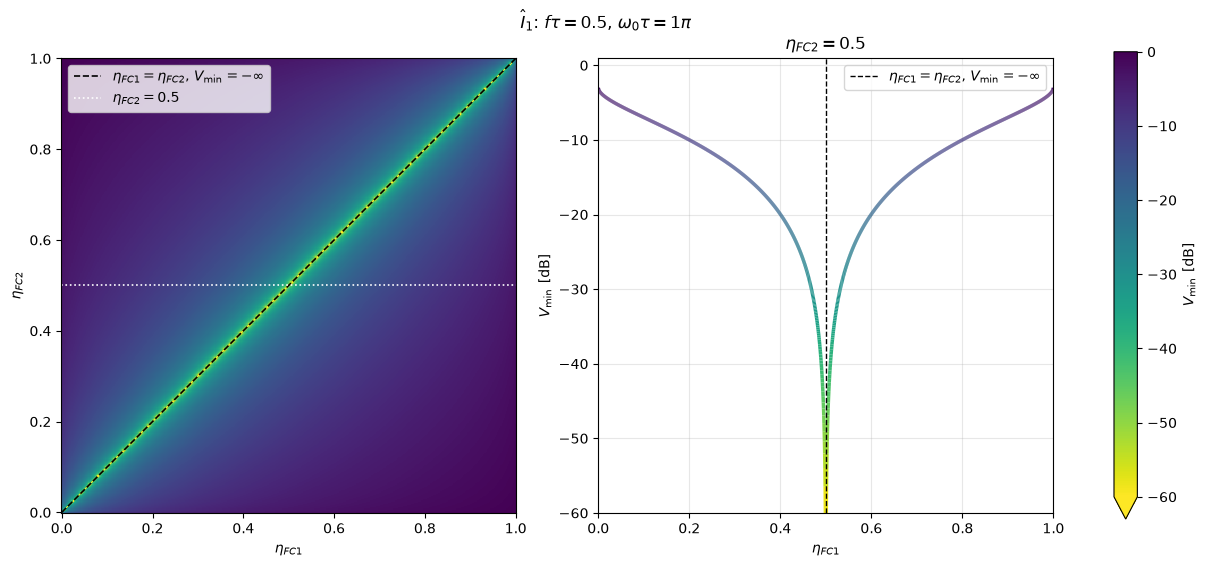

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

print("PD1:")

tau, f, phi0, e2_cut = 1e-9, 1/(2e-9), np.pi, 0.5   # phi0 = omega_0*tau mod 2pi
cmap, norm = 'viridis_r', Normalize(-60, 0)

def V_dB(e1, e2):
    z2, z3 = np.sqrt(e1*(1 - e2)), np.sqrt((1 - e1)*e2)
    c_sq = lambda s: z2**2 + z3**2 - 2*z2*z3*np.cos(phi0 + s*2*np.pi*f*tau)
    return 10*np.log10(np.clip(np.maximum(c_sq(+1), c_sq(-1)), 1e-30, None))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), layout='constrained')
# Heatmap
eta = np.linspace(0, 1, 401)
E1, E2 = np.meshgrid(eta, eta)
pc = ax1.pcolormesh(eta, eta, V_dB(E1, E2), cmap=cmap, norm=norm, shading='nearest')
ax1.plot([0, 1], [0, 1], 'k--', lw=1.2, label=r'$\eta_{FC1}=\eta_{FC2}$, $V_{\min}=-\infty$')
ax1.axhline(e2_cut, color='w', ls=':', lw=1.2, label=rf'$\eta_{{FC2}}={e2_cut}$')
ax1.set(xlabel=r'$\eta_{FC1}$', ylabel=r'$\eta_{FC2}$', aspect='equal')
ax1.legend(loc='upper left')

# Snitt, färgat med samma colormap
e1 = np.linspace(0, 1, 2001)
v = V_dB(e1, e2_cut)
pts = np.column_stack([e1, v]).reshape(-1, 1, 2)
lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap=cmap, norm=norm, lw=2.5)
lc.set_array(0.5*(v[:-1] + v[1:]))
ax2.add_collection(lc)
ax2.axvline(e2_cut, color='k', ls='--', lw=1, label=r'$\eta_{FC1}=\eta_{FC2}$, $V_{\min}=-\infty$')
ax2.set(xlabel=r'$\eta_{FC1}$', ylabel=r'$V_{\min}$ [dB]', xlim=(0, 1), ylim=(-60, 1),
        title=rf'$\eta_{{FC2}}={e2_cut}$')
ax2.set_box_aspect(1)
ax2.grid(alpha=0.3); ax2.legend()

fig.colorbar(pc, ax=[ax1, ax2], extend='min', label=r'$V_{\min}$ [dB]')
fig.suptitle(rf'$\hat I_1$: $f\tau={f*tau:.3g}$, $\omega_0\tau={phi0/np.pi:.3g}\pi$')
plt.show()



PD2:


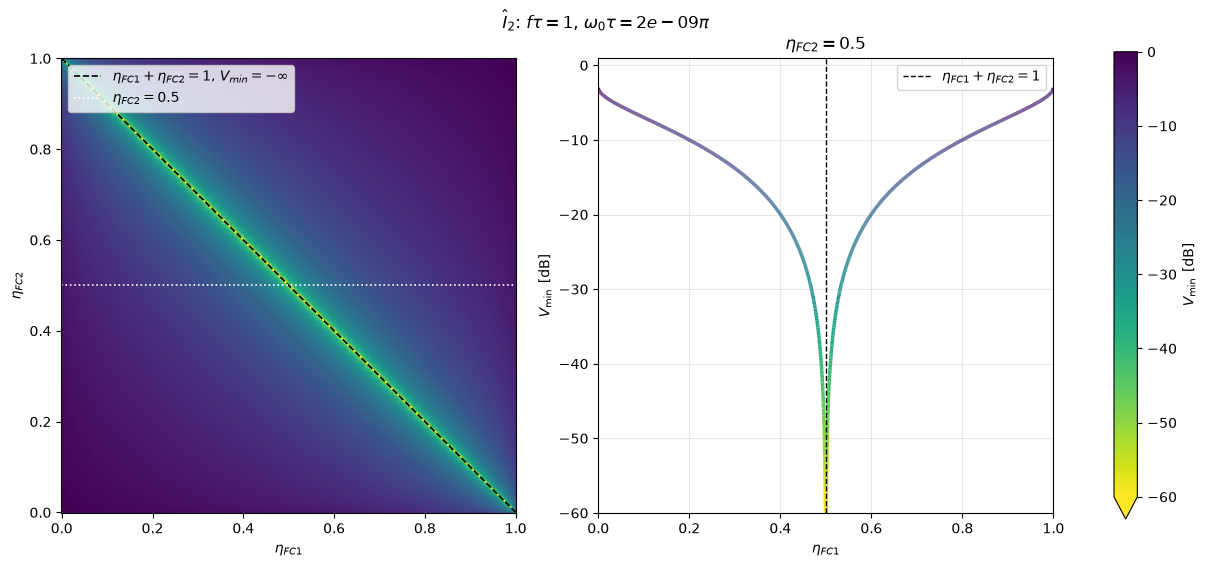

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

print("PD2:")

tau, f, phi0, e2_cut = 2e-9, 1/(2e-9), np.pi, 0.5  
cmap, norm = 'viridis_r', Normalize(-60, 0)

def V_dB(e1, e2):
    # PD2: c~_{1,2} = zeta_2 - zeta_3 exp(i(omega_0 ± Omega)tau),  V_min = 1 - min{|c~_1|^2, |c~_2|^2}
    z2, z3 = np.sqrt(e1*(1 - e2)), np.sqrt((1 - e1)*e2)
    c_sq = lambda s: z2**2 + z3**2 - 2*z2*z3*np.cos(phi0 + s*2*np.pi*f*tau)
    return 10*np.log10(np.clip(1 - np.minimum(c_sq(+1), c_sq(-1)), 1e-30, None))

# V_min = -inf kräver zeta_1 = zeta_4 (eta_FC1 + eta_FC2 = 1) och cos((omega_0 ± Omega)tau) = -1
perfect = np.allclose(np.cos(phi0 + np.array([1, -1])*2*np.pi*f*tau), -1)
line_lbl = r'$\eta_{FC1}+\eta_{FC2}=1$' + (r', $V_{min}=-\infty$' if perfect else '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), layout='constrained')
# Heatmap
eta = np.linspace(0, 1, 401)
E1, E2 = np.meshgrid(eta, eta)
pc = ax1.pcolormesh(eta, eta, V_dB(E1, E2), cmap=cmap, norm=norm, shading='nearest')
ax1.plot([0, 1], [1, 0], 'k--', lw=1.2, label=line_lbl)
ax1.axhline(e2_cut, color='w', ls=':', lw=1.2, label=rf'$\eta_{{FC2}}={e2_cut}$')
ax1.set(xlabel=r'$\eta_{FC1}$', ylabel=r'$\eta_{FC2}$', aspect='equal')
ax1.legend(loc='upper left')

# Snitt, färgat med samma colormap
e1 = np.linspace(0, 1, 2001)
v = V_dB(e1, e2_cut)
pts = np.column_stack([e1, v]).reshape(-1, 1, 2)
lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap=cmap, norm=norm, lw=2.5)
lc.set_array(0.5*(v[:-1] + v[1:]))
ax2.add_collection(lc)
ax2.axvline(1 - e2_cut, color='k', ls='--', lw=1, label=r'$\eta_{FC1}+\eta_{FC2}=1$')
ax2.set(xlabel=r'$\eta_{FC1}$', ylabel=r'$V_{\min}$ [dB]', xlim=(0, 1), ylim=(-60, 1),
        title=rf'$\eta_{{FC2}}={e2_cut}$')
ax2.set_box_aspect(1)
ax2.grid(alpha=0.3); ax2.legend()

fig.colorbar(pc, ax=[ax1, ax2], extend='min', label=r'$V_{\min}$ [dB]')
fig.suptitle(rf'$\hat I_2$: $f\tau={f*tau:.3g}$, $\omega_0\tau={phi0/np.pi*tau:.3g}\pi$')
plt.show()